the first thing to do is explore the data

In [1]:
import numpy as np 
import pandas as pd 

In [2]:
applications = pd.read_csv('dataset/application_record.csv')
records= pd.read_csv('dataset/credit_record.csv')
applications.shape, records.shape

((438557, 18), (1048575, 3))

In [3]:
applications.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [4]:
records.head()

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [5]:
len(records.ID.unique())

45985

In [6]:
records[records.ID.duplicated()]

,ID,MONTHS_BALANCE,STATUS
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
5,5001712,-1,C
6,5001712,-2,C
...,...,...,...
1048570,5150487,-25,C
1048571,5150487,-26,C
1048572,5150487,-27,C
1048573,5150487,-28,C


In [7]:
records[records.ID == 5001711]

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0


the way that the data is formatted is by giving the months balance for a certain month along with that month's status. 
to determine the creditworthiness of the customer, I will sum over the customer's past history to capture past missed payments. 

In [8]:
# check for null s
records.isnull().sum()

ID                0
MONTHS_BALANCE    0
STATUS            0
dtype: int64

In [9]:
# map the status to the right level 
# using ordinal encoding 
'''
the description for the feature is: 
0: 1-29 days past due 
1: 30-59 days past due 
2: 60-89 days overdue 
3: 90-119 days overdue 
4: 120-149 days overdue 
5: Overdue or bad debts, write-offs for more than 150 days 
C: paid off that month 
X: No loan for the month
'''

# convert this feature into: 
'''
the description for the feature is: 
0: No loan for the month
1: paid off that month 
2: 1-29 days past due 
3: 30-59 days past due 
4: 60-89 days overdue 
5: 90-119 days overdue 
6: 120-149 days overdue 
7: Overdue or bad debts, write-offs for more than 150 days 
'''

# higher values indicate lower creditworthiness 

from sklearn.preprocessing import OrdinalEncoder

In [10]:
categories= ['X' , 'C' ] +  [str(i) for i in range(0, 6 )]
print(categories)

encoder= OrdinalEncoder(categories= [categories])
records['status_encoded'] = encoder.fit_transform(records[['STATUS']])

records.head()

['X', 'C', '0', '1', '2', '3', '4', '5']


,ID,MONTHS_BALANCE,STATUS,status_encoded
0,5001711,0,X,0.0
1,5001711,-1,0,2.0
2,5001711,-2,0,2.0
3,5001711,-3,0,2.0
4,5001712,0,C,1.0


In [11]:
# begin summing over all the balance 
# higher score for status summed indicates lower creditworthiness 

records_grouped= records.groupby(by= 'ID' , axis = 0)
for i in records_grouped: 
    print(i) 
    break 

(5001711,         ID  MONTHS_BALANCE STATUS  status_encoded
0  5001711               0      X             0.0
1  5001711              -1      0             2.0
2  5001711              -2      0             2.0
3  5001711              -3      0             2.0)


/var/folders/j3/tjmkthlx1bn1l50f7k39nd480000gn/T/ipykernel_62701/1736641320.py:4: FutureWarning: The 'axis' keyword in DataFrame.groupby is deprecated and will be removed in a future version.
  records_grouped= records.groupby(by= 'ID' , axis = 0)


In [12]:
# to sum, use agg() --> for each group in groupby
# transform() --> for each instance in record 

records_grouped.status_encoded.agg(summed= 'sum')

,summed
ID,
5001711,6.0
5001712,29.0
5001713,0.0
5001714,0.0
5001715,0.0
...,...
5150482,30.0
5150483,0.0
5150484,25.0


In [13]:
# transform will be easier 
records['summed'] = records_grouped.status_encoded.transform('sum')
records.head()

,ID,MONTHS_BALANCE,STATUS,status_encoded,summed
0,5001711,0,X,0.0,6.0
1,5001711,-1,0,2.0,6.0
2,5001711,-2,0,2.0,6.0
3,5001711,-3,0,2.0,6.0
4,5001712,0,C,1.0,29.0


In [14]:
# now just get the unique ids 
creditworthiness= records.copy(deep = True)
# creditworthiness= creditworthiness[creditworthiness.ID.duplicated() == False ]
creditworthiness.drop_duplicates(subset='ID', inplace= True)
creditworthiness.drop(labels= ['MONTHS_BALANCE', 'STATUS', 'status_encoded'], axis= 1 , inplace= True) 
creditworthiness     


,ID,summed
0,5001711,6.0
4,5001712,29.0
23,5001713,0.0
45,5001714,0.0
60,5001715,0.0
...,...,...
1048494,5150482,30.0
1048512,5150483,0.0
1048530,5150484,25.0
1048543,5150485,4.0


to turn this into a classification problem, I want to view and understand the risk/creditworthiness of each customer
note that lower scores for summed indicate higher levels of creditworthiness 

In [15]:
import seaborn as sns 
import matplotlib.pyplot as plt

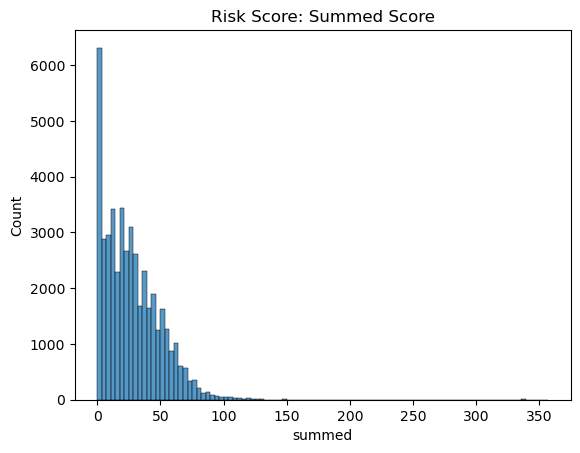

In [16]:
sns.histplot(creditworthiness.summed, bins= 100 )
plt.title('Risk Score: Summed Score')
plt.savefig('images/summed_score.png')
plt.show()

in order to split up the categorization of customers, the following will be the criteria: 
- 0 is very creditworthy -- automatic approval 
- the rest will be scored by placing into bins of standard deviations (excluding 0 risk scores)
    - describe is splittng into quartiles from median, instead use the mean and standard deviations to get the right bin boundaries 

In [17]:
score_mean= creditworthiness.summed.where(creditworthiness.summed > 0 ).mean()
score_std= creditworthiness.summed.where(creditworthiness.summed > 0 ).std()
score_mean, score_std

(np.float64(30.39402639388164), 21.51604929727674)

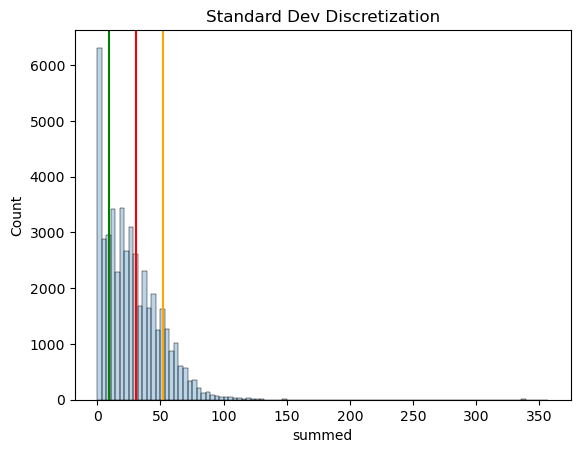

In [18]:
sns.histplot(creditworthiness.summed, bins  = 100 , alpha= .3,  label= '- summed score' )
plt.axvline(x= score_mean, label= 'medium', color= 'red')
plt.axvline(x= ( score_mean- score_std), label= 'low', color= 'green')
plt.axvline(x=  (score_mean+ score_std), label= 'high', color= 'orange')
# plt.legend()
plt.title('Standard Dev Discretization')
plt.savefig('images/standard_def_discretization.png')
plt.show()

the mapping will be as follows (feature summed), higher summed scores = more defaults on loans = higher risk : 
- 0 = no risk 
-  (0, score_mean- score_std] = low risk 
- (score_mean-score_std, score_mean] = medium low risk 
- (score_mean, score_mean-score_std] = medium high risk 
- (score_mean-score_std, inf) = high risk 

as a result, the classification will be over 5 labels 


In [19]:
# pd.cut is right selctive ( , ] ranges with right= True setting 
ranges= (-float('inf'),0, score_mean- score_std, score_mean, score_mean + score_std, float('inf'))
range_titles= ('none', 'low', 'medium_low', 'medium_high', 'high')

print(ranges)

creditworthiness['risk_level']= pd.cut(creditworthiness['summed'], bins=ranges, labels=range_titles, right= True)
creditworthiness


(-inf, 0, np.float64(8.877977096604898), np.float64(30.39402639388164), np.float64(51.91007569115838), inf)


,ID,summed,risk_level
0,5001711,6.0,low
4,5001712,29.0,medium_low
23,5001713,0.0,none
45,5001714,0.0,none
60,5001715,0.0,none
...,...,...,...
1048494,5150482,30.0,medium_low
1048512,5150483,0.0,none
1048530,5150484,25.0,medium_low
1048543,5150485,4.0,low


In [20]:
from sklearn.preprocessing import OrdinalEncoder
encoder= OrdinalEncoder(categories= [range_titles])
creditworthiness['risk'] = encoder.fit_transform(creditworthiness[['risk_level']])
creditworthiness.head()

,ID,summed,risk_level,risk
0,5001711,6.0,low,1.0
4,5001712,29.0,medium_low,2.0
23,5001713,0.0,none,0.0
45,5001714,0.0,none,0.0
60,5001715,0.0,none,0.0


In [21]:
creditworthiness.drop(labels= [ 'summed', 'risk_level'], axis= 1, inplace= True)
creditworthiness.head()

,ID,risk
0,5001711,1.0
4,5001712,2.0
23,5001713,0.0
45,5001714,0.0
60,5001715,0.0


creditworthiness is determined for the customers who already have a record of credit history
the next thing to do is look at application record, process it, and join with the ID if needed 

In [22]:
applications

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,6840104,M,N,Y,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0
438553,6840222,F,N,N,0,103500.0,Working,Secondary / secondary special,Single / not married,House / apartment,-15939,-3007,1,0,0,0,Laborers,1.0
438554,6841878,F,N,N,0,54000.0,Commercial associate,Higher education,Single / not married,With parents,-8169,-372,1,1,0,0,Sales staff,1.0
438555,6842765,F,N,Y,0,72000.0,Pensioner,Secondary / secondary special,Married,House / apartment,-21673,365243,1,0,0,0,NaN,2.0


### application record processing
convert the categorical features into proper encoding (label encoding, ordinal encoding, one hot encoding, ect...), then remove redundant features 

- this will eventually be done with sklearn Pipeline to simplify model deployment 
- first ensure that the way that each feature should be processed, data exploration 

In [23]:
applications.describe()

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
count,4.385570e+05,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.0,438557.000000,438557.000000,438557.000000,438557.000000
mean,6.022176e+06,0.427390,1.875243e+05,-15997.904649,60563.675328,1.0,0.206133,0.287771,0.108207,2.194465
std,5.716370e+05,0.724882,1.100869e+05,4185.030007,138767.799647,0.0,0.404527,0.452724,0.310642,0.897207
min,5.008804e+06,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.0,0.000000,0.000000,0.000000,1.000000
25%,5.609375e+06,0.000000,1.215000e+05,-19483.000000,-3103.000000,1.0,0.000000,0.000000,0.000000,2.000000
50%,6.047745e+06,0.000000,1.607805e+05,-15630.000000,-1467.000000,1.0,0.000000,0.000000,0.000000,2.000000
75%,6.456971e+06,1.000000,2.250000e+05,-12514.000000,-371.000000,1.0,0.000000,1.000000,0.000000,3.000000
max,7.999952e+06,19.000000,6.750000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000


In [24]:
applications.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-null  int64  
 15  FLAG_EMAIL       

In [25]:
categorical_features= []
for c in applications.columns: 
    if applications[c].dtype == 'object': 
        categorical_features.append(c)

categorical_features

['CODE_GENDER',
 'FLAG_OWN_CAR',
 'FLAG_OWN_REALTY',
 'NAME_INCOME_TYPE',
 'NAME_EDUCATION_TYPE',
 'NAME_FAMILY_STATUS',
 'NAME_HOUSING_TYPE',
 'OCCUPATION_TYPE']

these categorical features should be encoded in various ways which best fit the feature 
- code gender = nominal 
- flag own car = ordinal (0 no, 1 yes)
- flag own realty = ordinal (0 no, 1 yes)
- name income type = nominal 
- name education type = ordinal (0 for lowest)
- name family status = nominal 
- name housing status= nominal 
- occupation type = nominal (note there are nulls)

In [26]:
applications.NAME_EDUCATION_TYPE.unique()

array(['Higher education', 'Secondary / secondary special',
       'Incomplete higher', 'Lower secondary', 'Academic degree'],
      dtype=object)

In [27]:
# see how pipeline works, this is an example to be implemented further in the pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

ordinal_features= ['FLAG_OWN_CAR','FLAG_OWN_REALTY' ]


ordinal_preprocessor= OrdinalEncoder(categories=[['N', 'Y'], ['N', 'Y']]) # encoder for 2 features 

column_transformer = ColumnTransformer(
    transformers=[
    ('ordinal_cols', ordinal_preprocessor, ordinal_features ) # pass through multiple cols into encoder 
    # requires multiple features in categrories 
], 
remainder= 'passthrough', verbose_feature_names_out= False )

# make pipeline 
pipe= Pipeline(steps = [
    ('data_transform', column_transformer)
])

pipe.fit(applications)

,steps,"[('data_transform', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('ordinal_cols', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [28]:
column_transformer.get_feature_names_out()

array(['FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'ID', 'CODE_GENDER',
       'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'NAME_INCOME_TYPE',
       'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
       'DAYS_BIRTH', 'DAYS_EMPLOYED', 'FLAG_MOBIL', 'FLAG_WORK_PHONE',
       'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS'],
      dtype=object)

In [29]:
pd.DataFrame(pipe.transform(applications), columns=applications.columns)

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,1.0,1.0,5008804,M,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,1.0,1.0,5008805,M,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,1.0,1.0,5008806,M,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,0.0,1.0,5008808,F,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,0.0,1.0,5008809,F,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,0.0,1.0,6840104,M,0,135000.0,Pensioner,Secondary / secondary special,Separated,House / apartment,-22717,365243,1,0,0,0,NaN,1.0
438553,0.0,0.0,6840222,F,0,103500.0,Working,Secondary / secondary special,Single / not married,House / apartment,-15939,-3007,1,0,0,0,Laborers,1.0
438554,0.0,0.0,6841878,F,0,54000.0,Commercial associate,Higher education,Single / not married,With parents,-8169,-372,1,1,0,0,Sales staff,1.0
438555,0.0,1.0,6842765,F,0,72000.0,Pensioner,Secondary / secondary special,Married,House / apartment,-21673,365243,1,0,0,0,NaN,2.0


do the encoding entirely now, using the block code in data_processing 

In [234]:
from sklearn.impute import SimpleImputer 


In [235]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [236]:
%autoreload 3 -p 

In [243]:
from pipeline.data_processing import DataProcessing
encoder= DataProcessing(None).encoder_pipeline_simple()

pipeline= Pipeline(steps= [
    ('encoder', encoder)
])
pipeline.set_output(transform='pandas')
apps= pipeline.fit_transform(applications)
apps

Reloading 'pipeline.data_processing'.


,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
0,1.0,1.0,3.0,1.0,4.0,0.0,4.0,12.0,5008804,0,427500.0,-12005,-4542,1,1,0,0,2.0
1,1.0,1.0,3.0,1.0,4.0,0.0,4.0,12.0,5008805,0,427500.0,-12005,-4542,1,1,0,0,2.0
2,1.0,1.0,1.0,1.0,4.0,1.0,1.0,17.0,5008806,0,112500.0,-21474,-1134,1,0,0,0,2.0
3,0.0,1.0,1.0,0.0,0.0,3.0,1.0,15.0,5008808,0,270000.0,-19110,-3051,1,0,1,1,1.0
4,0.0,1.0,1.0,0.0,0.0,3.0,1.0,15.0,5008809,0,270000.0,-19110,-3051,1,0,1,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,0.0,1.0,1.0,1.0,1.0,2.0,1.0,12.0,6840104,0,135000.0,-22717,365243,1,0,0,0,1.0
438553,0.0,0.0,1.0,0.0,4.0,3.0,1.0,8.0,6840222,0,103500.0,-15939,-3007,1,0,0,0,1.0
438554,0.0,0.0,3.0,0.0,0.0,3.0,5.0,15.0,6841878,0,54000.0,-8169,-372,1,1,0,0,1.0
438555,0.0,1.0,1.0,0.0,1.0,1.0,1.0,12.0,6842765,0,72000.0,-21673,365243,1,0,0,0,2.0


this is the encoded application dataframe (no one hot encoding), now work on scaling 

In [244]:
for col in  apps.columns: 
    print(col, len(apps[col].value_counts()))

FLAG_OWN_CAR 2
FLAG_OWN_REALTY 2
NAME_EDUCATION_TYPE 5
CODE_GENDER 2
NAME_INCOME_TYPE 5
NAME_FAMILY_STATUS 5
NAME_HOUSING_TYPE 6
OCCUPATION_TYPE 19
ID 438510
CNT_CHILDREN 12
AMT_INCOME_TOTAL 866
DAYS_BIRTH 16379
DAYS_EMPLOYED 9406
FLAG_MOBIL 1
FLAG_WORK_PHONE 2
FLAG_PHONE 2
FLAG_EMAIL 2
CNT_FAM_MEMBERS 13


work on scaling now. scaling doesn't have to be done on target variable (customer risk), just on applications_processed 
- OCCUPATION_TYPE should be changed to onehot encodning because there are too many unique values, and I dont want to introduce ordinality where there shouldn't be 

<Axes: >

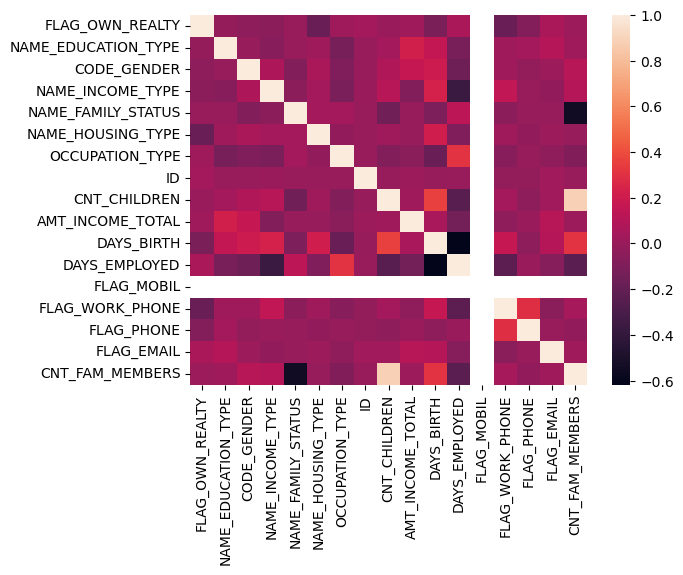

In [245]:
sns.heatmap(apps.iloc[:,1:].corr())

In [246]:
# the heatmap is indicating that FLAG_MOBIL is completely correlated with all other features, see why this is happending 
apps.corr()

,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
FLAG_OWN_CAR,1.000000,-0.001312,0.095991,0.346580,0.043117,-0.120279,0.004950,-0.092056,0.000063,0.115138,0.188203,0.163770,-0.165372,NaN,0.008061,-0.006606,0.038601,0.156943
FLAG_OWN_REALTY,-0.001312,1.000000,-0.013909,-0.041982,-0.044438,-0.003566,-0.177292,0.019738,0.042709,0.001560,0.025443,-0.106908,0.064281,NaN,-0.177372,-0.078227,0.062483,0.008070
NAME_EDUCATION_TYPE,0.095991,-0.013909,1.000000,-0.007651,-0.067178,-0.000157,0.016763,-0.125961,-0.001703,0.037715,0.221403,0.154548,-0.120340,NaN,0.016057,0.036010,0.102171,0.025593
CODE_GENDER,0.346580,-0.041982,-0.007651,1.000000,0.074654,-0.082324,0.062137,-0.097157,0.000545,0.086101,0.168807,0.193781,-0.167255,NaN,0.026050,-0.022300,0.011416,0.114188
NAME_INCOME_TYPE,0.043117,-0.044438,-0.067178,0.074654,1.000000,-0.049893,0.033717,-0.113069,0.005595,0.112210,-0.086957,0.231384,-0.368843,NaN,0.150464,0.000755,-0.027910,0.107944
NAME_FAMILY_STATUS,-0.120279,-0.003566,-0.000157,-0.082324,-0.049893,1.000000,0.041984,0.045575,-0.003128,-0.153769,-0.010109,-0.102399,0.133335,NaN,-0.049790,-0.009599,-0.005795,-0.545506
NAME_HOUSING_TYPE,0.004950,-0.177292,0.016763,0.062137,0.033717,0.041984,1.000000,-0.029275,-0.002425,0.025838,-0.009043,0.213982,-0.097314,NaN,0.026516,-0.025271,0.009193,-0.010546
OCCUPATION_TYPE,-0.092056,0.019738,-0.125961,-0.097157,-0.113069,0.045575,-0.029275,1.000000,-0.002382,-0.086147,-0.059578,-0.178600,0.305419,NaN,-0.064543,-0.006383,-0.031285,-0.088932
ID,0.000063,0.042709,-0.001703,0.000545,0.005595,-0.003128,-0.002425,-0.002382,1.000000,-0.005178,0.011179,-0.004994,-0.002467,NaN,-0.023319,-0.018992,0.032875,-0.001862
CNT_CHILDREN,0.115138,0.001560,0.037715,0.086101,0.112210,-0.153769,0.025838,-0.086147,-0.005178,1.000000,0.019177,0.349088,-0.241535,NaN,0.038418,-0.038266,0.028457,0.884781


In [247]:
apps.FLAG_MOBIL.value_counts()

FLAG_MOBIL
1    438557
Name: count, dtype: int64

the feature FLAG_MOBIL has only 1 value, which leads to nan in the corr. since this is caused by no variation the feature, the feature can be dropped. 
also, note that the famiily status and family member count aren't correlated at 1, instead the scale only goes up to .6, so it is ok to keep both features 

- it is safe to drop FLAG_MOBIL now 
- also redo encoding with one hot encoding for occupation types 

In [260]:
from utils import Utils 
from pipeline.data_processing import DataProcessing

encoder = DataProcessing(None).encoder_pipeline()
pipeline = Utils.pipeline_creator(steps_list = [('encoder', encoder)])

# print(pipeline)
apps= pipeline.fit_transform(applications)
apps.head()

,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE_Accountants,OCCUPATION_TYPE_Cleaning staff,OCCUPATION_TYPE_Cooking staff,...,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
0,1.0,1.0,3.0,1.0,4.0,0.0,4.0,0.0,0.0,0.0,...,5008804,0,427500.0,-12005,-4542,1,1,0,0,2.0
1,1.0,1.0,3.0,1.0,4.0,0.0,4.0,0.0,0.0,0.0,...,5008805,0,427500.0,-12005,-4542,1,1,0,0,2.0
2,1.0,1.0,1.0,1.0,4.0,1.0,1.0,0.0,0.0,0.0,...,5008806,0,112500.0,-21474,-1134,1,0,0,0,2.0
3,0.0,1.0,1.0,0.0,0.0,3.0,1.0,0.0,0.0,0.0,...,5008808,0,270000.0,-19110,-3051,1,0,1,1,1.0
4,0.0,1.0,1.0,0.0,0.0,3.0,1.0,0.0,0.0,0.0,...,5008809,0,270000.0,-19110,-3051,1,0,1,1,1.0


In [261]:
encoder.get_feature_names_out()

Reloading 'utils'.


array(['FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_EDUCATION_TYPE',
       'CODE_GENDER', 'NAME_INCOME_TYPE', 'NAME_FAMILY_STATUS',
       'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE_Accountants',
       'OCCUPATION_TYPE_Cleaning staff', 'OCCUPATION_TYPE_Cooking staff',
       'OCCUPATION_TYPE_Core staff', 'OCCUPATION_TYPE_Drivers',
       'OCCUPATION_TYPE_HR staff',
       'OCCUPATION_TYPE_High skill tech staff',
       'OCCUPATION_TYPE_IT staff', 'OCCUPATION_TYPE_Laborers',
       'OCCUPATION_TYPE_Low-skill Laborers', 'OCCUPATION_TYPE_Managers',
       'OCCUPATION_TYPE_Medicine staff',
       'OCCUPATION_TYPE_Private service staff',
       'OCCUPATION_TYPE_Realty agents', 'OCCUPATION_TYPE_Sales staff',
       'OCCUPATION_TYPE_Secretaries', 'OCCUPATION_TYPE_Security staff',
       'OCCUPATION_TYPE_Waiters/barmen staff', 'OCCUPATION_TYPE_nan',
       'ID', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'DAYS_BIRTH',
       'DAYS_EMPLOYED', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE',
       'FLAG_EMAIL'

the encoding is completely done now
now, look at scaling 

In [262]:
scaled= apps.copy(deep = True) 
scaled.head()

,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE_Accountants,OCCUPATION_TYPE_Cleaning staff,OCCUPATION_TYPE_Cooking staff,...,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
0,1.0,1.0,3.0,1.0,4.0,0.0,4.0,0.0,0.0,0.0,...,5008804,0,427500.0,-12005,-4542,1,1,0,0,2.0
1,1.0,1.0,3.0,1.0,4.0,0.0,4.0,0.0,0.0,0.0,...,5008805,0,427500.0,-12005,-4542,1,1,0,0,2.0
2,1.0,1.0,1.0,1.0,4.0,1.0,1.0,0.0,0.0,0.0,...,5008806,0,112500.0,-21474,-1134,1,0,0,0,2.0
3,0.0,1.0,1.0,0.0,0.0,3.0,1.0,0.0,0.0,0.0,...,5008808,0,270000.0,-19110,-3051,1,0,1,1,1.0
4,0.0,1.0,1.0,0.0,0.0,3.0,1.0,0.0,0.0,0.0,...,5008809,0,270000.0,-19110,-3051,1,0,1,1,1.0


In [263]:
scaled.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 36 columns):
 #   Column                                 Non-Null Count   Dtype  
---  ------                                 --------------   -----  
 0   FLAG_OWN_CAR                           438557 non-null  float64
 1   FLAG_OWN_REALTY                        438557 non-null  float64
 2   NAME_EDUCATION_TYPE                    438557 non-null  float64
 3   CODE_GENDER                            438557 non-null  float64
 4   NAME_INCOME_TYPE                       438557 non-null  float64
 5   NAME_FAMILY_STATUS                     438557 non-null  float64
 6   NAME_HOUSING_TYPE                      438557 non-null  float64
 7   OCCUPATION_TYPE_Accountants            438557 non-null  float64
 8   OCCUPATION_TYPE_Cleaning staff         438557 non-null  float64
 9   OCCUPATION_TYPE_Cooking staff          438557 non-null  float64
 10  OCCUPATION_TYPE_Core staff             438557 non-null  

- occupation types, flags don't have to be scaled, they are binary 
- id shouldn't be scaled either 
- counts should be scaled, depending on min max / normalization or sd scaling/ standardization 

In [264]:
scaling_features= ['CNT_CHILDREN','AMT_INCOME_TOTAL' ,  'DAYS_BIRTH','DAYS_EMPLOYED' , 'CNT_FAM_MEMBERS' ]

scaled[scaling_features].describe()

,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,CNT_FAM_MEMBERS
count,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.000000
mean,0.427390,1.875243e+05,-15997.904649,60563.675328,2.194465
std,0.724882,1.100869e+05,4185.030007,138767.799647,0.897207
min,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.000000
25%,0.000000,1.215000e+05,-19483.000000,-3103.000000,2.000000
50%,0.000000,1.607805e+05,-15630.000000,-1467.000000,2.000000
75%,1.000000,2.250000e+05,-12514.000000,-371.000000,3.000000
max,19.000000,6.750000e+06,-7489.000000,365243.000000,20.000000


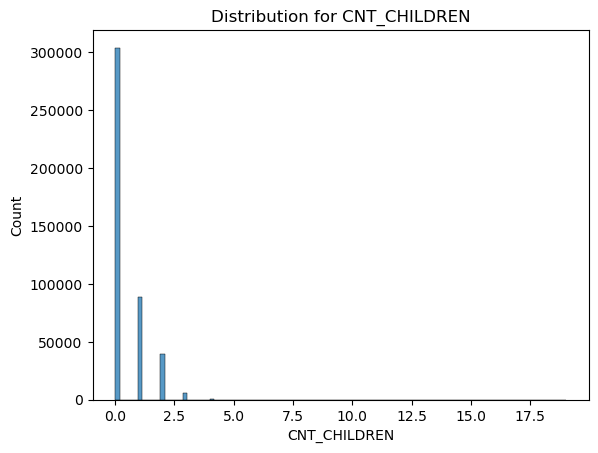

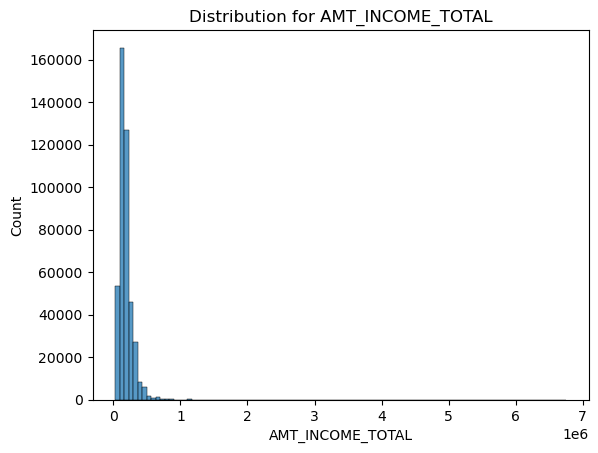

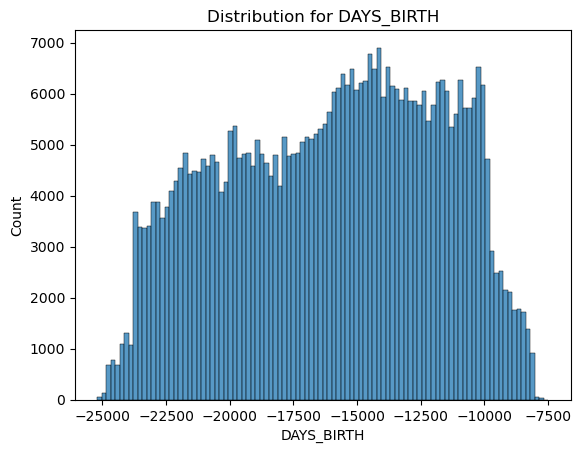

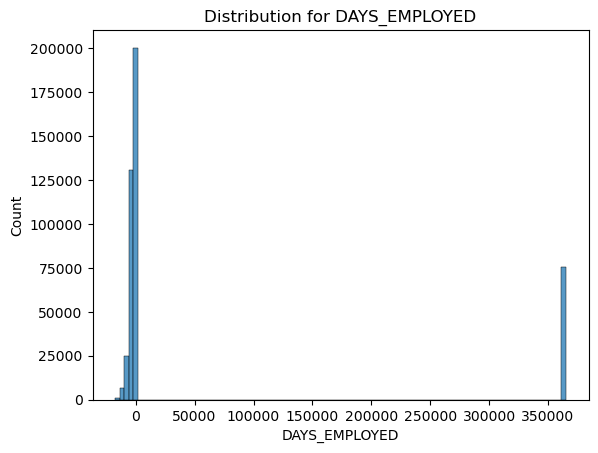

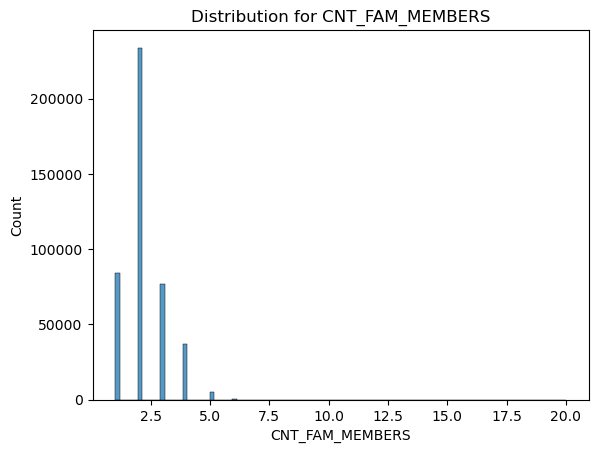

In [265]:
for feature in scaling_features: 
    sns.histplot(scaled[feature], bins= 100 )
    plt.title('Distribution for '+feature)
    plt.show()

the plots show that: 
- CNT_CHILDREN = robust scaling (not norm dist, but don't want to discount low number of children with minmax )
- AMT_INCOME_TOTAL= standard scaling (norm dist)
- DAYS_BIRTH= standard scaling (norm dist)
- DAYS_EMPLOYED = robust scaling for employed (negatuve vals), and create another binary feature to indicate unemplyment 
- CNT_FAM_MEMBERS = standard scaling


In [ ]:
# in order to do this, there has to be another feature created and added while the df is in the pipeline, see how to do this 
# create new feature for unemployed and add it to the df 
from sklearn.pipeline import FeatureUnion, FunctionTransformer

In [266]:
# identity transformer to preserve og df 
identity_transformer = FunctionTransformer(func= lambda inputs: inputs, feature_names_out='one-to-one')

# new feature transformer
def processing(inputs): # entire df, prevent lambda to save without loading error  
    df= inputs['DAYS_EMPLOYED'].apply(lambda row: 1 if row > 0 else 0 ) # return series 
    return df.values # call values to prevent clash between pandas col names 
     
def feat_names(transformer_info, cols): 
    return ['unemployed']

new_transformer= FunctionTransformer(func = processing, feature_names_out=feat_names)

# join transfomers with feature union now 
union= FeatureUnion(transformer_list=[
    ('idx_transform', identity_transformer), 
    ('new_feature', new_transformer)
], verbose_feature_names_out=False ) # don't append transformer name to the end 
union.set_output(transform='pandas') # return df, not array 

union.fit_transform(scaled[['DAYS_EMPLOYED', 'CNT_CHILDREN']])

,DAYS_EMPLOYED,CNT_CHILDREN,unemployed
0,-4542,0,0
1,-4542,0,0
2,-1134,0,0
3,-3051,0,0
4,-3051,0,0
...,...,...,...
438552,365243,0,1
438553,-3007,0,0
438554,-372,0,0
438555,365243,0,1


In [293]:
new_transformer.fit_transform(scaled[['DAYS_EMPLOYED', 'CNT_CHILDREN']])

,unemployed
0,0
1,0
2,0
3,0
4,0
...,...
438552,1
438553,0
438554,0
438555,1


In [267]:
union

,transformer_list,"[('idx_transform', ...), ('new_feature', ...)]"
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False
,func,<function <la...0x17d4e8b7130>
,inverse_func,None
,validate,False
,accept_sparse,False
,check_inverse,True
,feature_names_out,'one-to-one'


now do full scaling on output from encoding 

In [271]:
robust= ['CNT_CHILDREN', 'DAYS_EMPLOYED']
standard = ['AMT_INCOME_TOTAL', 'DAYS_BIRTH', 'CNT_FAM_MEMBERS'  ]
binary = ['unemployed']  # to be created from DAYS_EMPLOYED 
scaling_features

['CNT_CHILDREN',
 'AMT_INCOME_TOTAL',
 'DAYS_BIRTH',
 'DAYS_EMPLOYED',
 'CNT_FAM_MEMBERS']

In [268]:
apps # encoded, copy held in scaled 

,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE_Accountants,OCCUPATION_TYPE_Cleaning staff,OCCUPATION_TYPE_Cooking staff,...,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
0,1.0,1.0,3.0,1.0,4.0,0.0,4.0,0.0,0.0,0.0,...,5008804,0,427500.0,-12005,-4542,1,1,0,0,2.0
1,1.0,1.0,3.0,1.0,4.0,0.0,4.0,0.0,0.0,0.0,...,5008805,0,427500.0,-12005,-4542,1,1,0,0,2.0
2,1.0,1.0,1.0,1.0,4.0,1.0,1.0,0.0,0.0,0.0,...,5008806,0,112500.0,-21474,-1134,1,0,0,0,2.0
3,0.0,1.0,1.0,0.0,0.0,3.0,1.0,0.0,0.0,0.0,...,5008808,0,270000.0,-19110,-3051,1,0,1,1,1.0
4,0.0,1.0,1.0,0.0,0.0,3.0,1.0,0.0,0.0,0.0,...,5008809,0,270000.0,-19110,-3051,1,0,1,1,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,0.0,1.0,1.0,1.0,1.0,2.0,1.0,0.0,0.0,0.0,...,6840104,0,135000.0,-22717,365243,1,0,0,0,1.0
438553,0.0,0.0,1.0,0.0,4.0,3.0,1.0,0.0,0.0,0.0,...,6840222,0,103500.0,-15939,-3007,1,0,0,0,1.0
438554,0.0,0.0,3.0,0.0,0.0,3.0,5.0,0.0,0.0,0.0,...,6841878,0,54000.0,-8169,-372,1,1,0,0,1.0
438555,0.0,1.0,1.0,0.0,1.0,1.0,1.0,0.0,0.0,0.0,...,6842765,0,72000.0,-21673,365243,1,0,0,0,2.0


In [275]:
apps[scaling_features]

,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,CNT_FAM_MEMBERS
0,0,427500.0,-12005,-4542,2.0
1,0,427500.0,-12005,-4542,2.0
2,0,112500.0,-21474,-1134,2.0
3,0,270000.0,-19110,-3051,1.0
4,0,270000.0,-19110,-3051,1.0
...,...,...,...,...,...
438552,0,135000.0,-22717,365243,1.0
438553,0,103500.0,-15939,-3007,1.0
438554,0,54000.0,-8169,-372,1.0
438555,0,72000.0,-21673,365243,2.0


In [312]:
scaler= DataProcessing(None).scaler_pipeline()
pipeline= Utils.pipeline_creator([('scaler', scaler)])
pipeline
# pipeline.fit_transform(apps[scaling_features] )

,steps,"[('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,steps,"[('binary_transform', ...), ('column_transforms', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformer_list,"[('identity', ...), ('new_feat_unemployed', ...)]"
,n_jobs,None
,transformer_weights,None


In [313]:
pipeline['scaler']['binary_transform']['new_feat_unemployed'].get_feature_names_out()

array(['unemployed'], dtype=object)

In [ ]:
pipeline.fit_transform(apps[scaling_features]) 

,CNT_CHILDREN,DAYS_EMPLOYED,AMT_INCOME_TOTAL,DAYS_BIRTH,CNT_FAM_MEMBERS,unemployed
0,0.0,-1.125549,2.179879,0.954093,-0.216745,0
1,0.0,-1.125549,2.179879,0.954093,-0.216745,0
2,0.0,0.121889,-0.681502,-1.308498,-0.216745,0
3,0.0,-0.579795,0.749189,-0.743626,-1.331316,0
4,0.0,-0.579795,0.749189,-0.743626,-1.331316,0
...,...,...,...,...,...,...
438552,0.0,134.227672,-0.477117,-1.605509,-1.331316,1
438553,0.0,-0.563690,-0.763255,0.014075,-1.331316,0
438554,0.0,0.400805,-1.212901,1.870695,-1.331316,0
438555,0.0,134.227672,-1.049393,-1.356048,-0.216745,1


In [316]:
scaled= pipeline.fit_transform(scaled)
scaled.head()

,CNT_CHILDREN,DAYS_EMPLOYED,AMT_INCOME_TOTAL,DAYS_BIRTH,CNT_FAM_MEMBERS,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,...,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,unemployed
0,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,1.0,5008804,1,1,0,0,0
1,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,1.0,5008805,1,1,0,0,0
2,0.0,0.121889,-0.681502,-1.308498,-0.216745,1.0,1.0,1.0,1.0,4.0,...,0.0,1.0,0.0,0.0,5008806,1,0,0,0,0
3,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,5008808,1,0,1,1,0
4,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,5008809,1,0,1,1,0


the scaling pipeline is finished now 

#### now, check if the scaling pipeline and encoding pipeline can work together properly

In [318]:
temp= applications.copy(deep = True)
temp.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [320]:
dp= DataProcessing(None)
encoder=dp.encoder_pipeline()
scaler= dp.scaler_pipeline()
pipeline= Utils.pipeline_creator([
    ('encoder', encoder,) ,
    ('scaler', scaler )])

pipeline

,steps,"[('encoder', ...), ('scaler', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('ordinals', ...), ('nominals', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [322]:
temp= pipeline.fit_transform(temp)
temp.head()

,CNT_CHILDREN,DAYS_EMPLOYED,AMT_INCOME_TOTAL,DAYS_BIRTH,CNT_FAM_MEMBERS,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,...,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,unemployed
0,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,1.0,5008804,1,1,0,0,0
1,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,1.0,5008805,1,1,0,0,0
2,0.0,0.121889,-0.681502,-1.308498,-0.216745,1.0,1.0,1.0,1.0,4.0,...,0.0,1.0,0.0,0.0,5008806,1,0,0,0,0
3,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,5008808,1,0,1,1,0
4,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,5008809,1,0,1,1,0


In [324]:
all(temp== scaled)

True

the encoeder and scaler pipeline work well together, the last step of the pipeline will be done now 



I want practice making my own pipeline step, so I will make dropping the mobile flag as its own step in the pipeline
- the practice version is done here below 

In [326]:
from sklearn.base import BaseEstimator, TransformerMixin

In [364]:
# the pipeline step needs fit transform method and also a way to handle feature names 
temp = scaled.copy(deep = True )

class drops_function(BaseEstimator, TransformerMixin): 
    def __init__(self, drop_cols): # no args... 
        self.drop_cols= drop_cols 
        self.feat_names= [] # feature_names_in 

    def fit(self, X, y= None ): 
        # learn the feature names 
        self.feat_names= X.columns
        return self # nothing to be learned  
    def transform(self, X: pd.DataFrame, y= None ): 
        new_X= X.drop(columns= self.drop_cols, axis= 1,  inplace= False ) # create copy 
        self.feat_names= new_X.columns
        return new_X
    
    def get_feature_names_out(self, input_feats_unassigned): # needed for set_output() functoin for pipeline 
        return self.feat_names 
    

drops = drops_function(drop_cols=['FLAG_MOBIL'])
pipeline= Pipeline(steps= [('drops', drops)])
pipeline.set_output(transform='pandas')
pipeline.fit_transform(temp)

,CNT_CHILDREN,DAYS_EMPLOYED,AMT_INCOME_TOTAL,DAYS_BIRTH,CNT_FAM_MEMBERS,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,...,OCCUPATION_TYPE_Sales staff,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,unemployed
0,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008804,1,0,0,0
1,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008805,1,0,0,0
2,0.0,0.121889,-0.681502,-1.308498,-0.216745,1.0,1.0,1.0,1.0,4.0,...,0.0,0.0,1.0,0.0,0.0,5008806,0,0,0,0
3,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008808,0,1,1,0
4,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008809,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,0.0,134.227672,-0.477117,-1.605509,-1.331316,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,6840104,0,0,0,1
438553,0.0,-0.563690,-0.763255,0.014075,-1.331316,0.0,0.0,1.0,0.0,4.0,...,0.0,0.0,0.0,0.0,0.0,6840222,0,0,0,0
438554,0.0,0.400805,-1.212901,1.870695,-1.331316,0.0,0.0,3.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,6841878,1,0,0,0
438555,0.0,134.227672,-1.049393,-1.356048,-0.216745,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,6842765,0,0,0,1


In [357]:
pipeline.get_feature_names_out()

Index(['CNT_CHILDREN', 'DAYS_EMPLOYED', 'AMT_INCOME_TOTAL', 'DAYS_BIRTH',
       'CNT_FAM_MEMBERS', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY',
       'NAME_EDUCATION_TYPE', 'CODE_GENDER', 'NAME_INCOME_TYPE',
       'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE',
       'OCCUPATION_TYPE_Accountants', 'OCCUPATION_TYPE_Cleaning staff',
       'OCCUPATION_TYPE_Cooking staff', 'OCCUPATION_TYPE_Core staff',
       'OCCUPATION_TYPE_Drivers', 'OCCUPATION_TYPE_HR staff',
       'OCCUPATION_TYPE_High skill tech staff', 'OCCUPATION_TYPE_IT staff',
       'OCCUPATION_TYPE_Laborers', 'OCCUPATION_TYPE_Low-skill Laborers',
       'OCCUPATION_TYPE_Managers', 'OCCUPATION_TYPE_Medicine staff',
       'OCCUPATION_TYPE_Private service staff',
       'OCCUPATION_TYPE_Realty agents', 'OCCUPATION_TYPE_Sales staff',
       'OCCUPATION_TYPE_Secretaries', 'OCCUPATION_TYPE_Security staff',
       'OCCUPATION_TYPE_Waiters/barmen staff', 'OCCUPATION_TYPE_nan', 'ID',
       'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL', 'unempl

implmented in data_processing, see if this works correctly

In [362]:
drops = DataProcessing(None).drops_pipeline()
# pipeline= Utils.pipeline_creator([('dropping', drops)])

drops

Reloading 'pipeline.data_processing'.


,transformers,"[('dropping_cols', ...)]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False
,force_int_remainder_cols,'deprecated'
,drop_cols,['FLAG_MOBIL']


In [366]:
drops.fit_transform(temp)

,CNT_CHILDREN,DAYS_EMPLOYED,AMT_INCOME_TOTAL,DAYS_BIRTH,CNT_FAM_MEMBERS,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,...,OCCUPATION_TYPE_Sales staff,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,unemployed
0,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008804,1,0,0,0
1,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008805,1,0,0,0
2,0.0,0.121889,-0.681502,-1.308498,-0.216745,1.0,1.0,1.0,1.0,4.0,...,0.0,0.0,1.0,0.0,0.0,5008806,0,0,0,0
3,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008808,0,1,1,0
4,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008809,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,0.0,134.227672,-0.477117,-1.605509,-1.331316,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,6840104,0,0,0,1
438553,0.0,-0.563690,-0.763255,0.014075,-1.331316,0.0,0.0,1.0,0.0,4.0,...,0.0,0.0,0.0,0.0,0.0,6840222,0,0,0,0
438554,0.0,0.400805,-1.212901,1.870695,-1.331316,0.0,0.0,3.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,6841878,1,0,0,0
438555,0.0,134.227672,-1.049393,-1.356048,-0.216745,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,6842765,0,0,0,1


check that this custom class itegrates properly with the entire pipeline in data_processing

In [369]:
temp_final= DataProcessing(None).cc_applications_processing(applications)
temp_final.head()


Reloading 'pipeline.data_processing'.


,CNT_CHILDREN,DAYS_EMPLOYED,AMT_INCOME_TOTAL,DAYS_BIRTH,CNT_FAM_MEMBERS,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,...,OCCUPATION_TYPE_Sales staff,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,unemployed
0,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008804,1,0,0,0
1,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008805,1,0,0,0
2,0.0,0.121889,-0.681502,-1.308498,-0.216745,1.0,1.0,1.0,1.0,4.0,...,0.0,0.0,1.0,0.0,0.0,5008806,0,0,0,0
3,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008808,0,1,1,0
4,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008809,0,1,1,0


# the full data processing pipeline works well 
- has: encoding, scaling, dropping cols sub-pipelines 

# see the result of running the entire code from pipeline.py to see if it all flows together well 
the results are shown below, the pipeline works well 

In [370]:
final_apps= pd.read_csv('dataset/applications_processed.csv')
final_risk= pd.read_csv('dataset/customer_risk.csv')

In [371]:
final_apps

,CNT_CHILDREN,DAYS_EMPLOYED,AMT_INCOME_TOTAL,DAYS_BIRTH,CNT_FAM_MEMBERS,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,...,OCCUPATION_TYPE_Sales staff,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,unemployed
0,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008804,1,0,0,0
1,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008805,1,0,0,0
2,0.0,0.121889,-0.681502,-1.308498,-0.216745,1.0,1.0,1.0,1.0,4.0,...,0.0,0.0,1.0,0.0,0.0,5008806,0,0,0,0
3,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008808,0,1,1,0
4,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008809,0,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438552,0.0,134.227672,-0.477117,-1.605509,-1.331316,0.0,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,6840104,0,0,0,1
438553,0.0,-0.563690,-0.763255,0.014075,-1.331316,0.0,0.0,1.0,0.0,4.0,...,0.0,0.0,0.0,0.0,0.0,6840222,0,0,0,0
438554,0.0,0.400805,-1.212901,1.870695,-1.331316,0.0,0.0,3.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,6841878,1,0,0,0
438555,0.0,134.227672,-1.049393,-1.356048,-0.216745,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,6842765,0,0,0,1


In [372]:
final_risk

,ID,risk_level
0,5001711,1
1,5001712,2
2,5001713,0
3,5001714,0
4,5001715,0
...,...,...
45980,5150482,2
45981,5150483,0
45982,5150484,2
45983,5150485,1


In [374]:
pipeline= Utils.load_pipeline('pipeline/application_record_pipeline.pkl')
pipeline

,steps,"[('encoding', ...), ('scaling', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('ordinals', ...), ('nominals', ...), ...]"
,remainder,'passthrough'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,False


In [ ]:
final= pipeline.transform(applications) # checking if the transformations are working properly 
final.head()

,CNT_CHILDREN,DAYS_EMPLOYED,AMT_INCOME_TOTAL,DAYS_BIRTH,CNT_FAM_MEMBERS,FLAG_OWN_CAR,FLAG_OWN_REALTY,NAME_EDUCATION_TYPE,CODE_GENDER,NAME_INCOME_TYPE,...,OCCUPATION_TYPE_Sales staff,OCCUPATION_TYPE_Secretaries,OCCUPATION_TYPE_Security staff,OCCUPATION_TYPE_Waiters/barmen staff,OCCUPATION_TYPE_nan,ID,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,unemployed
0,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008804,1,0,0,0
1,0.0,-1.125549,2.179879,0.954093,-0.216745,1.0,1.0,3.0,1.0,4.0,...,0.0,0.0,0.0,0.0,1.0,5008805,1,0,0,0
2,0.0,0.121889,-0.681502,-1.308498,-0.216745,1.0,1.0,1.0,1.0,4.0,...,0.0,0.0,1.0,0.0,0.0,5008806,0,0,0,0
3,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008808,0,1,1,0
4,0.0,-0.579795,0.749189,-0.743626,-1.331316,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,5008809,0,1,1,0


In [377]:
all(final == final_apps)

True